# Обнаружение мошеннических вакансий

**Исследовательский вопрос.** Помогают ли embeddings текста вакансии лучше выявлять мошеннические объявления, чем TF-IDF?

Для сравнения используем логистическую регрессию на обоих представлениях текста. На embeddings также проверим Random Forest, чтобы сравнить два семейства классификаторов.

Источник данных — [Real or Fake? Fake Jobposting Prediction](https://www.kaggle.com/datasets/shivamb/real-or-fake-fake-jobposting-prediction). Одна строка соответствует одному объявлению. Целевая переменная `fraudulent` принимает значение `0` для реальной вакансии и `1` для мошеннической. `job_id` нужен для сопоставления строк.

### Подготовка окружения

В терминале из корня проекта выполните `python -m pip install -r requirements.txt` и выберите это окружение в Jupyter.

В проекте `lxml` используется для очистки HTML, `openai` и `python-dotenv` — для подготовки кеша embeddings через школьный API, `joblib` — для сохранения моделей. `ipykernel` запускает notebook, а `nbconvert` экспортирует его в HTML.

## 1. Исследовательский анализ данных

Проверяем размер таблицы, типы, пропуски и баланс классов. Сравниваем долю мошеннических вакансий в группах по логотипу, удалённой работе и типу занятости.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_PATH = Path('data/fake_job_postings.csv')
jobs = pd.read_csv(DATA_PATH)

n_rows, n_columns = jobs.shape
print(f'Размер таблицы: {n_rows} строк × {n_columns} колонок')
jobs[['job_id', 'title', 'location', 'employment_type', 'fraudulent']].head(5)

Размер таблицы: 17880 строк × 18 колонок


,job_id,title,location,employment_type,fraudulent
0,1,Marketing Intern,"US, NY, New York",Other,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Full-time,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Full-time,0
4,5,Bill Review Manager,"US, FL, Fort Worth",Full-time,0


### Типы и пропуски

В таблице показаны типы и пропуски для всех колонок, а также доли пропусков по классам. Пустые строки и строки из одних пробелов тоже считаем пропусками. На графике показаны поля, в которых есть пропуски.

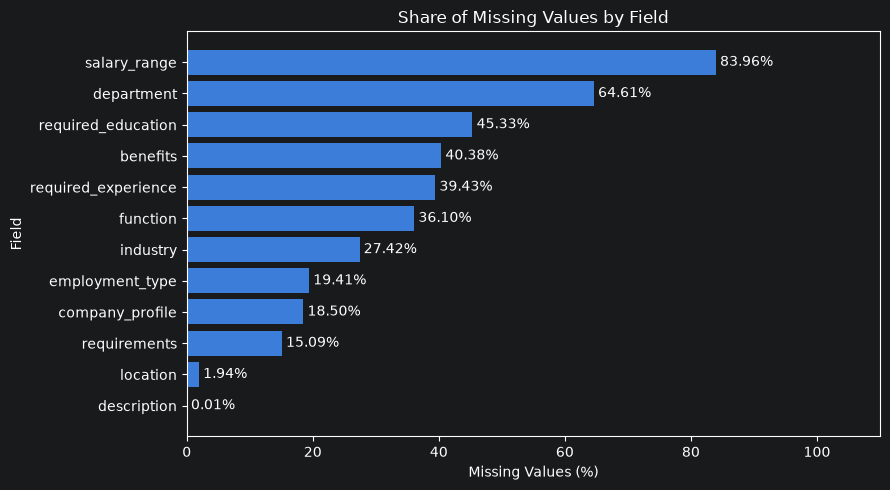

,Тип,Число пропусков,"Пропуски, %","Пропуски у реальных, %","Пропуски у мошеннических, %"
salary_range,str,15012,83.96,84.45,74.25
department,str,11553,64.61,64.78,61.32
required_education,str,8105,45.33,44.99,52.08
benefits,str,7220,40.38,40.30,42.03
required_experience,str,7050,39.43,38.88,50.23
function,str,6455,36.10,35.96,38.91
industry,str,4903,27.42,27.20,31.76
employment_type,str,3471,19.41,18.98,27.83
company_profile,str,3308,18.50,15.99,67.78
requirements,str,2698,15.09,14.95,17.78


In [2]:
missing = jobs.replace(r"^\s*$", pd.NA, regex=True).isna()
by_class = missing.groupby(jobs["fraudulent"], observed=True).mean().T
by_class = by_class.reindex(columns=[0, 1]) * 100

data_profile = pd.DataFrame({
    "Тип": jobs.dtypes.astype(str),
    "Число пропусков": missing.sum(),
    "Пропуски, %": missing.mean() * 100,
    "Пропуски у реальных, %": by_class[0],
    "Пропуски у мошеннических, %": by_class[1],
}).round(2).sort_values("Число пропусков", ascending=False)

with_missing = data_profile.loc[data_profile["Число пропусков"] > 0]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(with_missing.index, with_missing["Пропуски, %"], color="#3b7dd8")
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f%%", padding=3)
ax.set(
    title="Share of Missing Values by Field",
    xlabel="Missing Values (%)",
    ylabel="Field",
    xlim=(0, 110),
    xticks=range(0, 101, 20),
)
fig.tight_layout()
plt.show()

data_profile

Чаще всего отсутствуют `salary_range` (84,0%) и `department` (64,6%). Пропуски есть и в полях, из которых соберём общий текст. Например, `benefits` отсутствует примерно у 40% вакансий. При подготовке текста заменим пустые поля пустой строкой, чтобы сохранить объявление, если у него есть другой текст.

### Баланс классов

            Count  Percent
fraudulent                
0           17014    95.16
1             866     4.84


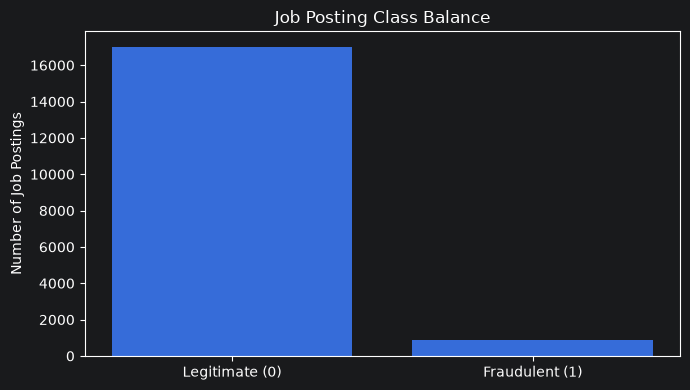

Always predicting legitimate gives 95.16% accuracy.


In [3]:
def analyze_class_balance(df):
    counts = df["fraudulent"].value_counts().reindex([0, 1], fill_value=0)
    percentages = counts / len(df) * 100
    summary = pd.DataFrame({"Count": counts, "Percent": percentages.round(2)})
    print(summary)

    plt.figure(figsize=(7, 4))
    plt.bar(["Legitimate (0)", "Fraudulent (1)"], counts)
    plt.title("Job Posting Class Balance")
    plt.ylabel("Number of Job Postings")
    plt.tight_layout()
    plt.show()

    print(f"Always predicting legitimate gives {percentages[0]:.2f}% accuracy.")
    return summary

class_balance = analyze_class_balance(jobs)

Мошеннических вакансий всего **4,84%**. Модель, которая называет все вакансии реальными, получит **95,16% accuracy** на исходных данных и пропустит все 866 мошеннических объявлений. Поэтому для сравнения моделей выберем **Average Precision (AP)**. Она оценивает, насколько хорошо модель ставит мошеннические вакансии выше реальных, учитывая precision и recall при разных порогах. Accuracy также приведём в итоговой таблице.

### Характеристики вакансии

В каждой группе показываем доли реальных и мошеннических вакансий. Подписи под столбцами указывают размер группы. Для логотипа и удалённой работы 0 означает отсутствие признака, 1 — наличие.

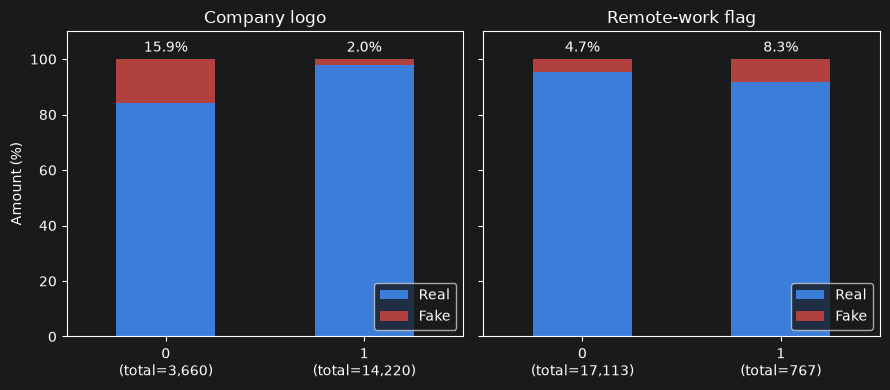

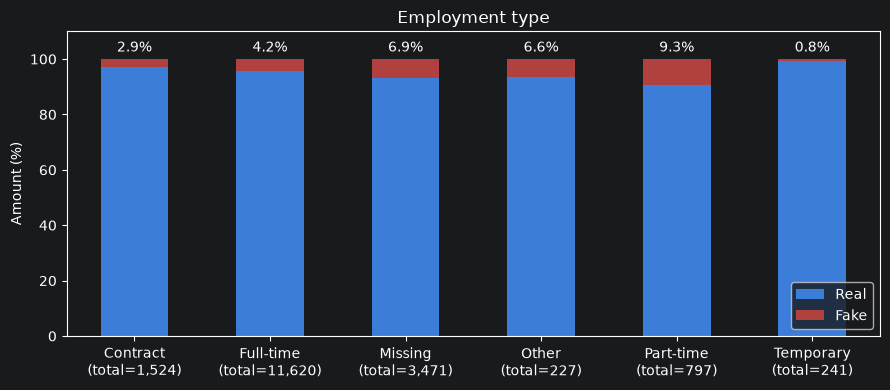

In [4]:
def fraud_bars(jobs, feature, ax, title):
    groups = jobs[feature]
    if groups.isna().any():
        groups = groups.astype("string").fillna("Missing")
    counts = pd.crosstab(groups, jobs["fraudulent"])
    counts = counts.reindex(columns=[0, 1], fill_value=0)
    counts.columns = ["Real", "Fake"]
    totals = counts.sum(axis=1)
    shares = counts.div(totals, axis=0) * 100
    shares.index = [f"{group}\n(total={n:,})" for group, n in totals.items()]
    shares.plot.bar(
        stacked=True, ax=ax, color=["#3b7dd8", "#b0413e"], rot=0
    )
    ax.bar_label(
        ax.containers[1],
        labels=[f"{pct:.1f}%" for pct in shares["Fake"]],
        padding=3,
    )
    ax.set(title=title, xlabel="", ylabel="Amount (%)", ylim=(0, 110))
    ax.set_yticks(range(0, 101, 20))
    ax.legend(loc="lower right")
    return counts


def plot_job_features(jobs):
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
    fraud_bars(jobs, "has_company_logo", axes[0], "Company logo")
    fraud_bars(jobs, "telecommuting", axes[1], "Remote-work flag")
    fig.tight_layout()

    fig, ax = plt.subplots(figsize=(9, 4))
    fraud_bars(jobs, "employment_type", ax, "Employment type")
    fig.tight_layout()

plot_job_features(jobs)
plt.show()

Без логотипа доля мошеннических объявлений составила **15,9%**, с логотипом — **2,0%**. Среди вакансий с отметкой об удалённой работе мошеннических **8,3%**, среди остальных — **4,7%**. В каждой группе реальные вакансии остаются большинством.

Для Part-time доля мошеннических вакансий выше, чем для Full-time (**9,3%** против **4,2%**). Размеры групп тоже различаются. Такие связи описывают исходный датасет. Основной эксперимент сравнит два способа представления одного и того же текста вакансии.

## 2. Подготовка данных

### Очистка текста вакансий

Для каждой вакансии используем заголовок, профиль компании, описание, требования и условия. Пустое поле заменяем пустой строкой. Из заполненных полей извлекаем текст без HTML-разметки и выравниваем пробелы.

В pandas объединяем поля в столбец «text» и считаем число слов. Для анализа заполненности также считаем количество заполненных текстовых и категориальных полей. Через фильтр оставляем вакансии, у которых после очистки есть текст.

In [5]:
import re
from html import unescape

from lxml import html

TEXT_COLUMNS = ['title', 'company_profile', 'description', 'requirements', 'benefits']
METADATA_COLUMNS = [
    'location', 'department', 'salary_range', 'employment_type',
    'required_experience', 'required_education', 'industry', 'function',
]

def clean_html_text(value):
    if pd.isna(value):
        return ''

    text = unescape(str(value))
    if re.search(r'<(?:/?[a-zA-Z][^>]*|!--.*?)>', text, flags=re.S):
        document = html.fragment_fromstring(text, create_parent='div')
        for element in document.xpath('.//script | .//style'):
            element.drop_tree()
        text = ' '.join(document.itertext())

    return ' '.join(text.split())

In [6]:
cleaned_jobs = jobs.copy()
for column in TEXT_COLUMNS:
    cleaned_jobs[column] = jobs[column].map(clean_html_text)
text_fields = cleaned_jobs[TEXT_COLUMNS]

metadata_fields = cleaned_jobs[METADATA_COLUMNS].copy()
for column in METADATA_COLUMNS:
    metadata_fields[column] = metadata_fields[column].fillna("").str.strip()

cleaned_jobs['text'] = text_fields.agg(' '.join, axis=1).str.strip()
cleaned_jobs['word_count'] = cleaned_jobs['text'].str.split().str.len()
cleaned_jobs['filled_fields'] = (
    text_fields.ne('').sum(axis=1) + metadata_fields.ne('').sum(axis=1)
)

has_text = cleaned_jobs['text'].ne('')
text_jobs = cleaned_jobs.loc[has_text].copy()

print(f'Исходных объявлений: {len(jobs):,}')
print(f'Исключено объявлений с пустым текстом: {(~has_text).sum():,}')

Исходных объявлений: 17,880
Исключено объявлений с пустым текстом: 0


### Длина текста после очистки

Сравниваем число слов по классам и долю мошеннических объявлений в интервалах длины. Оба графика используют непустые тексты до удаления дублей.

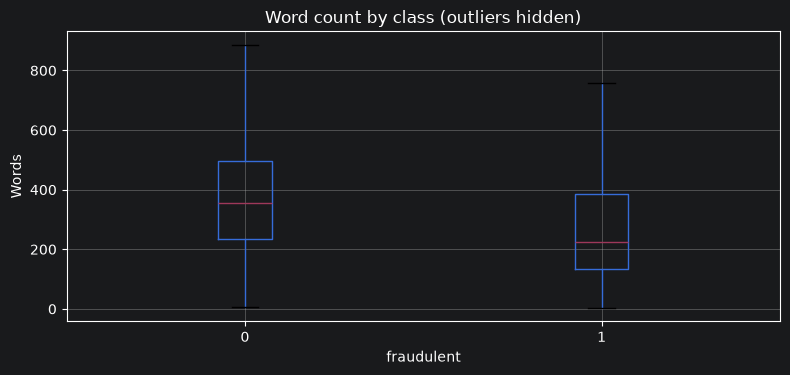

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
text_jobs.boxplot(column="word_count", by="fraudulent", ax=ax, showfliers=False)
ax.set(title="Word count by class (outliers hidden)", xlabel="fraudulent",
       ylabel="Words")
fig.suptitle("")
fig.tight_layout()
plt.show()

Медиана длины у мошеннических вакансий ниже. Длины текстов заметно перекрываются, поэтому по длине одной вакансии класс определить сложно. На графике скрыты точки за пределами усов, чтобы лучше показать основное распределение.

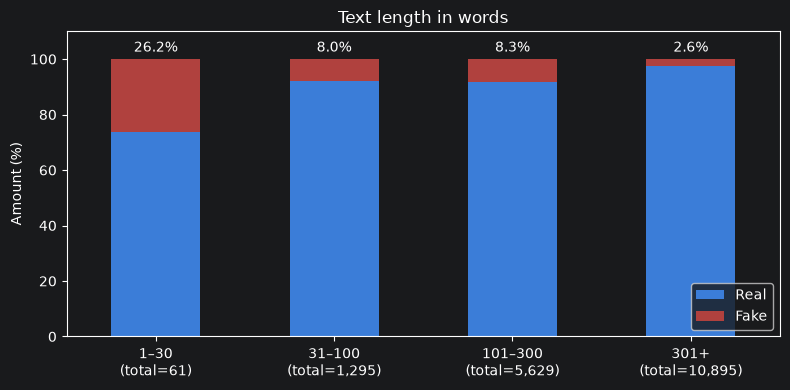

,Real,Fake
text_length_group,,
1–30,45,16
31–100,1192,103
101–300,5164,465
301+,10613,282


In [8]:
def plot_text_length(jobs):
    groups = pd.cut(
        jobs["word_count"],
        bins=[0, 30, 100, 300, float("inf")],
        labels=["1–30", "31–100", "101–300", "301+"],
    )

    fig, ax = plt.subplots(figsize=(8, 4))
    counts = fraud_bars(
        jobs.assign(text_length_group=groups),
        "text_length_group",
        ax,
        "Text length in words",
    )
    fig.tight_layout()
    return counts


length_counts = plot_text_length(text_jobs)
plt.show()
length_counts

Среди текстов от 1 до 30 слов **16 из 61** оказались мошенническими (**26,2%**). Среди текстов от 301 слова доля составила **2,6%**. Самая короткая группа небольшая. Сохраняем её при очистке, поскольку удаление коротких текстов исключило бы и мошеннические объявления.